# Track 2: Catching bursts of fraud as they happen

Starter notebook. Run it from top to bottom in a fresh Colab session. It
clones your repository, downloads the data, loads it in a memory-friendly
way, shows the basic numbers, and hands you the fixed test split. Then it
stops, and the `TODO D1.x` cells mark where your work begins.

**Data:** The same Sparkov files as Track 1, read as each card's sequence of transactions, oldest first.

The two files are about 500 MB unpacked and take a few minutes to download the first time. Sequences add memory on top: roughly rows × window × features × 4 bytes.

On this track the unit the system acts on is the **card**, not the transaction: it decides when to hold a card, and the metric counts how many frauds got through before it did.

Before you change anything, save your own copy with File → Save a copy in
GitHub and give it a path with your name in it, such as
`notebooks/track02_<yourname>.ipynb`. The original stays clean so a
teammate can start from it.

## 1. Setup

Edit `REPO_URL` to your team's repository, then run the cell. It clones the
repository into this Colab session (or pulls, if it's already here), moves
into it and installs the two or three packages Colab doesn't ship with.

Tokens come from **Colab Secrets** (the key icon in the left sidebar), never
from a cell. The names it looks for are `GITHUB_TOKEN`, `KAGGLE_USERNAME` and
`KAGGLE_KEY`. If one is missing, the error says which. The getting-started
notebook shows how to create them.

In [ ]:
REPO_URL = "https://github.com/williamli218/mais202-team-2-fraud-bursts"   # <- edit this line

import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if "<your-team>" in REPO_URL:
        raise ValueError("Edit REPO_URL at the top of this cell to your team's repository first.")
    from google.colab import userdata

    def _secret(name):
        try:
            return userdata.get(name)
        except Exception as e:
            raise RuntimeError(
                f"Colab Secret {name} is missing or not shared with this notebook. "
                "Open the key icon in the left sidebar, add it, and switch on Notebook access."
            ) from e

    token = _secret("GITHUB_TOKEN")
    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        os.environ[name] = _secret(name)

    repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.isdir(repo):
        auth_url = REPO_URL.replace("https://", f"https://{token}@")
        subprocess.run(["git", "clone", "--quiet", auth_url], check=True)
    os.chdir(repo)
    subprocess.run(["git", "pull", "--quiet"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # Not in Colab: assume this notebook is open from inside the repository.
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
import config
print("repository:", os.getcwd(), "| template version:", config.TEMPLATE_VERSION)
print("TRACK in config.py:", config.TRACK, "" if config.TRACK else "<- one teammate sets this and pushes config.py")

repository: /content/mais202-team-2-fraud-bursts | template version: 2026-11-06
TRACK in config.py: 2 


In [ ]:
!git config user.name "William Li"
!git config user.email "williamli218@users.noreply.github.com"

## 2. Download and load

Same loader as Track 1; see `src/data.py`.

In [ ]:
from src import data

pool, test = data.load_track02()

Using Colab cache for faster access to the 'fraud-detection' dataset.
Using Colab cache for faster access to the 'fraud-detection' dataset.


Optional: cache a copy in Google Drive. Colab's disk is wiped between
sessions, so the download runs again every time. If that's slow for your
track, mount Drive and point `config.DATA_DIR` at a folder there before
loading. Everything below works the same either way.

In [ ]:
USE_DRIVE = False   # set True to keep the data between Colab sessions

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    from pathlib import Path
    drive.mount("/content/drive")
    config.DATA_DIR = Path("/content/drive/MyDrive/mais202_data")
    config.DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("data will be cached in", config.DATA_DIR)

## 3. Quick look

Numbers only; plots are D1.3.

In [ ]:
data.quick_look(pool, "is_fraud", "train pool")
data.quick_look(test, "is_fraud", "test")
attacked = pool.groupby("cc_num", observed=True)["is_fraud"].max()
print(f"cards in pool: {len(attacked):,}, attacked (at least one fraud): {int(attacked.sum()):,}")


train pool: 1,296,675 rows x 19 columns, 335 MB in memory
columns: trans_date_trans_time, cc_num, merchant, category, amt, gender, city, state, zip, lat, long, city_pop, job, dob, trans_num, unix_time, merch_lat, merch_long, is_fraud
is_fraud == 1: 7,506 of 1,296,675 (0.579%)
test: 555,719 rows x 19 columns, 144 MB in memory
columns: trans_date_trans_time, cc_num, merchant, category, amt, gender, city, state, zip, lat, long, city_pop, job, dob, trans_num, unix_time, merch_lat, merch_long, is_fraud
is_fraud == 1: 2,145 of 555,719 (0.386%)
cards in pool: 983, attacked (at least one fraud): 762


## 4. The fixed test split

The loader returned two tables: a train pool and a test set. **The test set
is not to be touched until Deliverable 3.** Not for a plot, not for checking
a feature, not for picking a threshold. It's fixed in `src/data.py` so that
your D1, D2 and D3 numbers are measured on the same thing, and it only
measures anything if nobody has looked at it.

Your validation set comes out of the train pool, and that's the next cell.

In [ ]:
print("train pool:", pool["trans_date_trans_time"].min(), "->", pool["trans_date_trans_time"].max())
print("test:      ", test["trans_date_trans_time"].min(), "->", test["trans_date_trans_time"].max())

import pandas as pd
t = pd.to_datetime(pool["trans_date_trans_time"])
month = t.dt.to_period("M")

fraud = pool[pool["is_fraud"] == 1]
first_fraud = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].min()

monthly = pd.DataFrame({
    "rows": pool.groupby(month).size(),
    "fraud_tx": pool.groupby(month)["is_fraud"].sum(),
    "attacks_starting": first_fraud.dt.to_period("M").value_counts(),
}).fillna(0).astype(int)
monthly["fraud_rate_%"] = (100 * monthly["fraud_tx"] / monthly["rows"]).round(3)
monthly

fr = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].agg(["min", "max"])

rows = []
for cut in pd.date_range("2019-09-01", "2020-04-01", freq="MS"):
    rows.append({
        "cut": cut.date(),
        "train_months": round((cut - t.min()).days / 30.4, 1),
        "valid_months": round((t.max() - cut).days / 30.4, 1),
        "attacks_in_valid": int((fr["min"] >= cut).sum()),
        "straddling_cut": int(((fr["min"] < cut) & (fr["max"] >= cut)).sum()),
    })
pd.DataFrame(rows)

train pool: 2019-01-01 00:00:18 -> 2020-06-21 12:13:37
test:       2020-06-21 12:14:25 -> 2020-12-31 23:59:34


,cut,train_months,valid_months,attacks_in_valid,straddling_cut
0,2019-09-01,8.0,9.7,423,3
1,2019-10-01,8.9,8.7,382,0
2,2019-11-01,10.0,7.7,332,3
3,2019-12-01,11.0,6.7,294,3
4,2020-01-01,12.0,5.7,235,2
5,2020-02-01,13.0,4.6,197,3
6,2020-03-01,13.9,3.7,165,1
7,2020-04-01,15.0,2.7,121,3


## 5. Your validation split (TODO D1.2)

Carve a validation set out of `pool`, in `src/split.py`, as the function
`make_validation_split(pool)`. It lives in `src/` and not in this notebook
so that every teammate, every notebook and every model uses the same split;
three slightly different splits in three notebooks is how a team ends up
arguing about whose number is right.

For tracks with a time column, the validation set is the latest part of
the training period, so the model is judged on data from after what it
learned from. A random split on time-ordered data gives a validation score
that looks great and a test score that collapses. Tracks without time (6)
split at random, stratified on the label.

`split.check_split()` runs the two checks the deliverable asks for (no
identifier in both parts; training ends before validation begins), and
`pytest tests/test_leakage.py` runs them on your split. Green there is
D1.2 done.

In [ ]:
from src import split

# TODO D1.2: write make_validation_split() in src/split.py, then run this cell.
try:
    train, valid = split.make_validation_split(pool)
except NotImplementedError as e:
    train = valid = None
    print(e)
else:
    split.check_split(train, valid, *split.default_columns())
    print(f"train: {len(train):,} rows, valid: {len(valid):,} rows; both checks passed")

train: 924,850 rows, valid: 371,825 rows; both checks passed


Think about the validation split at the card level too: the metric is per
attacked card, so a validation period with only a handful of attacked cards
gives a noisy number. Count them before you settle on a cut.

In [ ]:
!python -m pytest -q tests/test_leakage.py

....                                                                     [100%]
4 passed in 0.90s


In [ ]:
!git config user.name "William Li"
!git config user.email "williamli218@users.noreply.github.com"

In [ ]:
   !git add src/split.py
   !git commit -m "D1.2: time-based validation split at 2020-01-01"
   !git push

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   src/features.py

no changes added to commit (use "git add" and/or "git commit -a")
Everything up-to-date


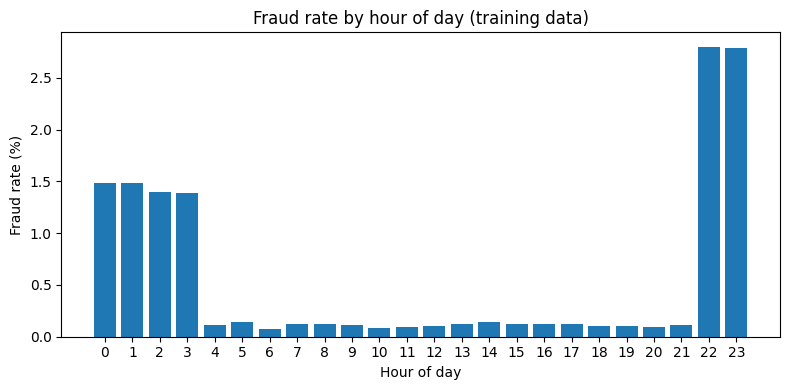

In [ ]:
import os
import matplotlib.pyplot as plt
os.makedirs("reports/figures", exist_ok=True)

hour = pd.to_datetime(train["trans_date_trans_time"]).dt.hour
rate = train.groupby(hour)["is_fraud"].mean() * 100

plt.figure(figsize=(8, 4))
plt.bar(rate.index, rate.values)
plt.xticks(range(24))
plt.xlabel("Hour of day")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud rate by hour of day (training data)")
plt.tight_layout()
plt.savefig("reports/figures/fraud_rate_by_hour.png", dpi=150)
plt.show()

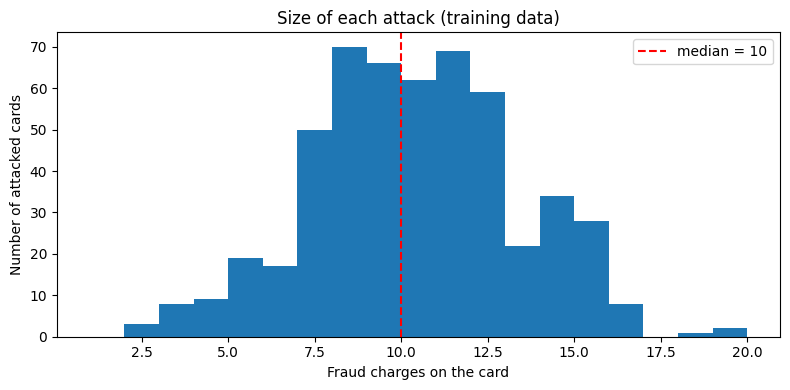

In [ ]:
per_card = train[train["is_fraud"] == 1].groupby("cc_num", observed=True).size()

plt.figure(figsize=(8, 4))
plt.hist(per_card, bins=range(1, per_card.max() + 2))
plt.axvline(per_card.median(), color="red", linestyle="--", label=f"median = {per_card.median():.0f}")
plt.xlabel("Fraud charges on the card")
plt.ylabel("Number of attacked cards")
plt.title("Size of each attack (training data)")
plt.legend()
plt.tight_layout()
plt.savefig("reports/figures/frauds_per_attacked_card.png", dpi=150)
plt.show()

In [ ]:
!git add reports/figures/*.png
!git commit -m "D1.3: exploration plots"
!git push

[main ad64298] D1.3: exploration plots
 2 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 reports/figures/fraud_rate_by_hour.png
 create mode 100644 reports/figures/frauds_per_attacked_card.png
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 56.26 KiB | 9.38 MiB/s, done.
Total 6 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   22c4d5c..ad64298  main -> main


## 6. Features (TODO D1.4)

Features live in `src/features.py`, one function each, so that the
notebook, the tests and `predict()` all build them the same way. The file
has one worked example to show the shape. It's an example of a feature
function, not a feature you should rely on. Write at least three of your
own there, then call `build_features` here to check they behave.

In [ ]:
from src import features

# TODO D1.4: write your features in src/features.py, add them to build_features(), then run this.
features.build_features(pool.head(10))

,log_seconds_since_prev,transaction_count_past_24h,spend_past_24h,hour_of_day,amount_is_round
0,14.767941,NaN,NaN,0,0
1,14.767941,NaN,NaN,0,0
2,14.767941,NaN,NaN,0,0
3,14.767941,NaN,NaN,0,1
4,14.767941,NaN,NaN,0,0
5,14.767941,NaN,NaN,0,0
6,14.767941,NaN,NaN,0,0
7,14.767941,NaN,NaN,0,0
8,14.767941,NaN,NaN,0,0
9,14.767941,NaN,NaN,0,0


In [ ]:
import importlib
importlib.reload(features)
features.build_features(pool.head(5000)).describe()

,log_seconds_since_prev,transaction_count_past_24h,spend_past_24h,hour_of_day,amount_is_round
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,10.650291,2.855800,193.779221,12.384400,0.012000
std,2.291038,1.797914,255.659409,7.014448,0.108896
min,1.609438,1.000000,1.040000,0.000000,0.000000
25%,9.263881,1.000000,62.252499,6.000000,0.000000
50%,10.331040,2.000000,128.904999,13.000000,0.000000
75%,11.411283,4.000000,232.950005,18.000000,0.000000
max,14.767941,12.000000,4955.439941,23.000000,1.000000


In [ ]:
importlib.reload(features)
feats = features.build_features(pool)
f_train = feats.loc[train.index].copy()
f_train["is_fraud"] = train["is_fraud"].values
f_train.groupby("is_fraud").median().T

is_fraud,0,1
log_seconds_since_prev,9.665611,8.521383
transaction_count_past_24h,4.000000,5.000000
spend_past_24h,244.430008,2260.680176
hour_of_day,14.000000,22.000000
amt,47.180000,390.875000


In [ ]:
!git add src/features.py
!git commit -m "D1.4: card-history features (gap, 24h count, 24h spend, hour)"
!git push

[main 15842e9] D1.4: card-history features (gap, 24h count, 24h spend, hour)
 1 file changed, 43 insertions(+), 2 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.07 KiB | 1.07 MiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   a097127..15842e9  main -> main


## 7. The trivial baseline (TODO D1.5)

The baseline calls every row legitimate: every score is 0. It's here to be
scored with your metric and with accuracy, side by side, before you train
anything. On this track it will look very accurate and catch nothing. That
gap is the point of the evaluation metric section of your proposal.

Write your track's metric in `src/metrics.py` until
`pytest tests/test_metrics.py` is green. Then uncomment the lines below and
run them on **your validation set**.

In [ ]:
!python -m pytest -q tests/test_metrics.py

ssssss......ssssssssssssssssssssssssssssssssssssssss                     [100%]
6 passed, 46 skipped in 1.26s


In [ ]:
from src.models import always_legitimate
from sklearn.metrics import accuracy_score

baseline_scores = always_legitimate(len(pool))
print("baseline scores:", baseline_scores[:5], "... (all zeros)")
labelled = pool["is_fraud"] != -1          # only matters on Track 9, where -1 means unknown
print("accuracy on the train pool if we predict 'legitimate' everywhere:",
      round(accuracy_score(pool["is_fraud"][labelled], (baseline_scores[labelled] >= 0.5).astype(int)), 4))

# TODO D1.5: once `pytest tests/test_metrics.py` is green, score the baseline on YOUR validation set:
from src import metrics
y_valid = valid["is_fraud"].to_numpy()
s_valid = always_legitimate(len(valid))
print("headline metric:", metrics.median_frauds_before_hold(y_valid, s_valid, valid["cc_num"].to_numpy(), max_legit_hold_rate=0.01))
print("accuracy:       ", accuracy_score(y_valid, (s_valid >= 0.5).astype(int)))

baseline scores: [0. 0. 0. 0. 0.] ... (all zeros)
accuracy on the train pool if we predict 'legitimate' everywhere: 0.9942
headline metric: 9.0
accuracy:        0.993851946480199


In [ ]:
!git add src/metrics.py src/features.py
!git commit -m "D1.5: median_frauds_before_hold metric"
!git push

[main 22c4d5c] D1.5: median_frauds_before_hold metric
 1 file changed, 26 insertions(+), 1 deletion(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 880 bytes | 220.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   15842e9..22c4d5c  main -> main


## 8. Sequences

`make_sequences` turns the table into one fixed-length window per
transaction: the card's last `n` transactions ending at it, oldest first,
zero-padded while the card has fewer than `n`. `X` is what a sequence model
reads; `y` is the label of the last transaction in each window; `meta` keeps
the card, the time and how many rows in the window are real.

Only numeric columns go in. Encoding `category`, `merchant` or the hour of
day into numbers is part of D1.4. Start with a small `n` and one or two
features; the array grows fast.

In [ ]:
X, y, meta = data.make_sequences(pool, n=10, feature_cols=["amt"])
print("X:", X.shape, X.dtype, "| y:", y.shape, "| meta columns:", list(meta.columns))
print("memory for X: %.0f MB" % (X.nbytes / 1e6))
i = int(meta.index[meta["n_valid"] == 10][0])   # a window with no padding
print("one window (amount only), oldest first:", X[i, :, 0].round(2))

X: (1296675, 10, 1) float32 | y: (1296675,) | meta columns: ['cc_num', 'unix_time', 'is_fraud', 'n_valid']
memory for X: 52 MB
one window (amount only), oldest first: [ 46.97  64.48  51.39  68.04  73.57  40.31 217.54   4.98  34.13  17.22]


## 9. Running the tests

The metric tests fail until D1.5 is done; that's expected, and the message
says which function to write. The leakage tests on the provided split should
pass now. `test_predict.py` skips until D2.6.

In [ ]:
!python -m pytest -q tests/test_metrics.py tests/test_leakage.py

ssssss......ssssssssssssssssssssssssssssssssssssssss....                 [100%]
10 passed, 46 skipped in 0.74s


## Where to go next

In this order, because each step uses the one before:

1. `make_validation_split` in `src/split.py` until `pytest tests/test_leakage.py` is green (D1.2).
2. Two exploration plots, in your own notebook (D1.3).
3. Three features in `src/features.py` (D1.4).
4. The metric in `src/metrics.py` until the tests pass, then the baseline
   scored on validation with accuracy beside it (D1.5).
5. The cost table in `src/decision.py` (D1.6).
6. Write the report under the headings in `reports/Project Proposal.md`.

Work in a copy of this notebook with your name in the filename. Push code
in `src/` with git from a cell; save notebooks with File → Save a copy in
GitHub.

In [ ]:
!git pull --rebase

remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 8 (delta 6), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (8/8), 1.99 KiB | 1020.00 KiB/s, done.
From https://github.com/williamli218/mais202-team-2-fraud-bursts
   ad64298..a3e695b  main       -> origin/main
Successfully rebased and updated refs/heads/main.


In [ ]:
!git push

Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 454 bytes | 454.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   a3e695b..0dce1ce  main -> main


In [ ]:
!git add src/decision.py
!git commit -m "D1.6: cost table"
!git push

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
To https://github.com/williamli218/mais202-team-2-fraud-bursts
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/williamli218/mais202-team-2-fraud-bursts'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


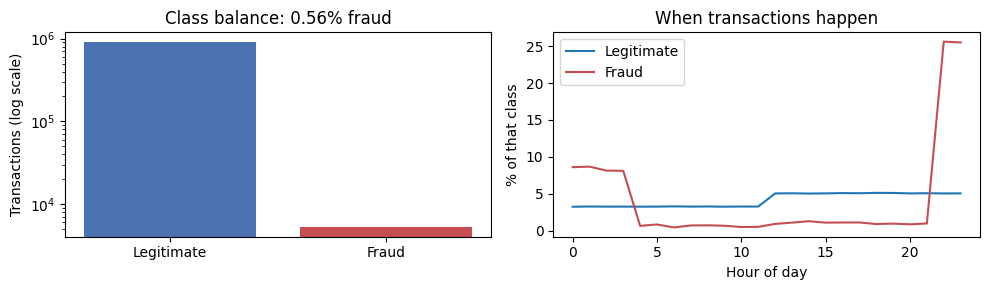

In [ ]:
import os
import matplotlib.pyplot as plt
os.makedirs("reports/figures", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))

# Left: class balance
counts = train["is_fraud"].value_counts().sort_index()
ax1.bar(["Legitimate", "Fraud"], counts.values, color=["#4C72B0", "#C44E52"])
ax1.set_yscale("log")
ax1.set_ylabel("Transactions (log scale)")
ax1.set_title(f"Class balance: {100 * train['is_fraud'].mean():.2f}% fraud")

# Right: share of each class by hour
hour = pd.to_datetime(train["trans_date_trans_time"]).dt.hour
by_hour = pd.crosstab(hour, train["is_fraud"], normalize="columns") * 100
ax2.plot(by_hour.index, by_hour[0], label="Legitimate")
ax2.plot(by_hour.index, by_hour[1], label="Fraud", color="#C44E52")
ax2.set_xlabel("Hour of day")
ax2.set_ylabel("% of that class")
ax2.set_title("When transactions happen")
ax2.legend()

plt.tight_layout()
plt.savefig("reports/figures/eda.png", dpi=150)
plt.show()

In [ ]:
!git add src/models.py
!git commit -m "D2.1: logistic regression model"
!git push

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date


In [ ]:
!pwd
!grep -n "train_logistic_regression" src/models.py
!git status --short

/content/mais202-team-2-fraud-bursts/mais202-team-2-fraud-bursts/mais202-team-2-fraud-bursts


In [ ]:
import os
os.chdir("/content/mais202-team-2-fraud-bursts")
!pwd
!grep -n "train_logistic_regression" src/models.py
!git status --short

/content/mais202-team-2-fraud-bursts
30:def train_logistic_regression(X_train, y_train):
 M src/models.py
?? mais202-team-2-fraud-bursts/


In [ ]:
!git config user.name "William Li"
!git config user.email "williamli218@users.noreply.github.com"
!git add src/models.py
!git commit -m "D2.1: logistic regression training function"
!git push

[main c03ba03] D2.1: logistic regression training function
 1 file changed, 12 insertions(+)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 593 bytes | 296.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   e4ca816..c03ba03  main -> main


In [ ]:
print(sorted(pool["category"].astype(str).unique()))
print(pool["category"].astype(str).nunique(), "categories")

['entertainment', 'food_dining', 'gas_transport', 'grocery_net', 'grocery_pos', 'health_fitness', 'home', 'kids_pets', 'misc_net', 'misc_pos', 'personal_care', 'shopping_net', 'shopping_pos', 'travel']
14 categories


In [ ]:
import numpy as np
dist = np.sqrt((train["lat"] - train["merch_lat"])**2 + (train["long"] - train["merch_long"])**2)
print(dist.groupby(train["is_fraud"]).median())

is_fraud
0    0.798367
1    0.802354
dtype: float32


In [ ]:
import pandas as pd
hour = pd.to_datetime(train["trans_date_trans_time"]).dt.hour
legit = train["is_fraud"] == 0
region = pd.cut(train["long"], bins=[-180, -115, -100, -85, -60],
                labels=["far west", "mountain", "central", "east"])
print(hour[legit].groupby(region[legit], observed=True).mean().round(2))

long
far west    12.68
mountain    12.85
central     12.89
east        12.73
Name: trans_date_trans_time, dtype: float64


In [ ]:
!git add src/features.py
!git commit -m "D2: improved features (is_night, amount vs recent mean, categories, log amounts)"
!git push

[main 8371606] D2: improved features (is_night, amount vs recent mean, categories, log amounts)
 1 file changed, 48 insertions(+), 44 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.29 KiB | 1.29 MiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   e4b49a0..8371606  main -> main


In [ ]:
from src import features, models, metrics

feats = features.build_features(pool)
X_train, X_valid = feats.loc[train.index], feats.loc[valid.index]

model = models.train_logistic_regression(X_train, train["is_fraud"])
s_valid = model.predict_proba(X_valid)[:, 1]

print("headline metric:", metrics.median_frauds_before_hold(
    valid["is_fraud"], s_valid, valid["cc_num"], max_legit_hold_rate=0.01))

headline metric: 9.0


In [ ]:
from sklearn.metrics import roc_auc_score
import numpy as np, pandas as pd

print("transaction-level AUC:", round(roc_auc_score(valid["is_fraud"], s_valid), 4))

v = pd.DataFrame({"card": valid["cc_num"].to_numpy(), "y": valid["is_fraud"].to_numpy(), "s": s_valid})
per_card = v.groupby("card", observed=True).agg(attacked=("y", "max"), max_score=("s", "max"))
legit_max = per_card.loc[per_card["attacked"] == 0, "max_score"]
fraud_max = v[v["y"] == 1].groupby("card", observed=True)["s"].max()

print("legit cards:", len(legit_max), "| attacked cards:", len(fraud_max))
print("legit cards' max score, 50/90/99th pct:", legit_max.quantile([.5, .9, .99]).round(4).tolist())
print("attacked cards' best fraud score, 10/50/90th pct:", fraud_max.quantile([.1, .5, .9]).round(4).tolist())

transaction-level AUC: 0.9887
legit cards: 694 | attacked cards: 237
legit cards' max score, 50/90/99th pct: [0.9883, 0.999, 0.9998]
attacked cards' best fraud score, 10/50/90th pct: [0.9961, 0.9985, 0.9995]


In [ ]:
top_legit = valid[(valid["is_fraud"] == 0) & (s_valid > 0.999)]
print(len(top_legit), "legit transactions scored > 0.999")
print(top_legit[["amt", "category"]].describe(include="all").T[["count", "mean", "50%", "top"]])
print(valid.loc[valid["is_fraud"] == 1, "amt"].describe().round(0))

106 legit transactions scored > 0.999
          count         mean          50%     top
amt       106.0  4532.125977  3848.639893     NaN
category    106          NaN          NaN  travel
count    2286.0
mean      534.0
std       385.0
min         1.0
25%       259.0
50%       426.0
75%       896.0
max      1376.0
Name: amt, dtype: float64


In [ ]:
print(train.loc[train["is_fraud"] == 1, "amt"].describe().round(0))

count    5220.0
mean      530.0
std       393.0
min         1.0
25%       231.0
50%       391.0
75%       903.0
max      1372.0
Name: amt, dtype: float64


In [ ]:
!git add src/features.py
!git commit -m "D2: amount bands replace linear amount"
!git push

[main bb821af] D2: amount bands replace linear amount
 1 file changed, 16 insertions(+), 1 deletion(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 755 bytes | 755.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   8371606..bb821af  main -> main


In [ ]:
import importlib
importlib.reload(features)
feats = features.build_features(pool)
X_train, X_valid = feats.loc[train.index], feats.loc[valid.index]
model = models.train_logistic_regression(X_train, train["is_fraud"])
s_valid = model.predict_proba(X_valid)[:, 1]
print("headline metric:", metrics.median_frauds_before_hold(
    valid["is_fraud"], s_valid, valid["cc_num"], max_legit_hold_rate=0.01))

headline metric: 9.0


In [ ]:
v = pd.DataFrame({"card": valid["cc_num"].to_numpy(), "s": s_valid})
s_smooth = v.groupby("card", observed=True)["s"].transform(lambda x: x.rolling(3, min_periods=1).mean()).to_numpy()

print("smoothed, last 3:", metrics.median_frauds_before_hold(
    valid["is_fraud"], s_smooth, valid["cc_num"], max_legit_hold_rate=0.01))

smoothed, last 3: 3.0


In [ ]:
for k in [2, 3, 5]:
    s_k = v.groupby("card", observed=True)["s"].transform(lambda x: x.rolling(k, min_periods=1).mean()).to_numpy()
    print(k, metrics.median_frauds_before_hold(valid["is_fraud"], s_k, valid["cc_num"], max_legit_hold_rate=0.01))

2 5.0
3 3.0
5 4.0


In [ ]:
import joblib
joblib.dump(model, "models/logreg.joblib")

!git add src/models.py models/logreg.joblib
!git commit -m "D2.1: logistic regression + 3-transaction score smoothing (median 3)"
!git push

[main 8f3dd1b] D2.1: logistic regression + 3-transaction score smoothing (median 3)
 2 files changed, 10 insertions(+)
 create mode 100644 models/logreg.joblib
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 2.74 KiB | 2.74 MiB/s, done.
Total 6 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   bb821af..8f3dd1b  main -> main


In [ ]:
import json
scaler = model.named_steps["standardscaler"]
lr = model.named_steps["logisticregression"]

params = {
    "features": list(X_train.columns),
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coef": lr.coef_[0].tolist(),
    "intercept": float(lr.intercept_[0]),
    "smooth_k": 3,
}
with open("models/logistic_regression.json", "w") as f:
    json.dump(params, f, indent=2)

In [ ]:
import importlib
importlib.reload(models)
p = models.load_logistic_regression()
print("max difference:", np.abs(models.logistic_regression_scores(p, X_valid) - s_valid).max())

max difference: 1.330152067380297e-07


In [ ]:
!git add src/models.py models/logreg.json
!git commit -m "D2.1: save logistic regression as JSON, add loader"
!git push

[main 512d02e] D2.1: save logistic regression as JSON, add loader
 2 files changed, 125 insertions(+)
 create mode 100644 models/logreg.json
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 1.89 KiB | 1.89 MiB/s, done.
Total 6 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   8f3dd1b..512d02e  main -> main


In [ ]:
!head -3 experiments/log.csv

date,author,model,settings,split,metric,value,notes


In [ ]:
import csv, datetime

def log_run(model, settings, metric, value, notes=""):
    with open("experiments/log.csv", "a", newline="") as f:
        csv.writer(f).writerow([datetime.date.today().isoformat(), "William Li",
                                model, settings, "valid", metric, value, notes])

In [ ]:
log_run("all_legitimate", "score 0 everywhere", "median_frauds_before_hold", 9.0, "D1.5 baseline")
log_run("all_legitimate", "score 0 everywhere", "accuracy", 0.9939)
log_run("logistic_regression", "improved features, class_weight=balanced", "median_frauds_before_hold", 9.0)
log_run("logistic_regression", "+ amount bands", "median_frauds_before_hold", 9.0, "AUC 0.989")
for k, val in [(2, 5.0), (3, 3.0), (5, 4.0)]:
    log_run("logistic_regression", f"+ amount bands + smoothing k={k}", "median_frauds_before_hold", val)

In [ ]:
!git add experiments/log.csv
!git commit -m "Log D1 baseline and D2 logistic regression runs"
!git push

[main e05ea78] Log D1 baseline and D2 logistic regression runs
 1 file changed, 7 insertions(+)
To https://github.com/williamli218/mais202-team-2-fraud-bursts
 ! [rejected]        main -> main (fetch first)
error: failed to push some refs to 'https://github.com/williamli218/mais202-team-2-fraud-bursts'
hint: Updates were rejected because the remote contains work that you do not
hint: have locally. This is usually caused by another repository pushing to
hint: the same ref. If you want to integrate the remote changes, use
hint: 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [ ]:
!git pull --rebase
!git push

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 7 (delta 3), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 3.00 KiB | 1024.00 KiB/s, done.
From https://github.com/williamli218/mais202-team-2-fraud-bursts
   512d02e..557a90b  main       -> origin/main
error: The following untracked working tree files would be overwritten by checkout:
	models/logistic_regression.json
Please move or remove them before you switch branches.
Aborting
error: could not detach HEAD
To https://github.com/williamli218/mais202-team-2-fraud-bursts
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/williamli218/mais202-team-2-fraud-bursts'
hint: Updates were rejected because the tip of your current branch is behind
hint: its remote counterpart. If you want to integrate the remote changes,
hint: use 'git pull' before pushing again.
hint: Se

In [ ]:
!mv models/logistic_regression.json /tmp/lr_local.json
!git pull --rebase
!git push
!cmp /tmp/lr_local.json models/logistic_regression.json && echo "same file"

Successfully rebased and updated refs/heads/main.
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 602 bytes | 602.00 KiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   557a90b..5a1a349  main -> main
cmp: EOF on /tmp/lr_local.json after byte 2527, in line 112


In [ ]:
import json
scaler = model.named_steps["standardscaler"]
lr = model.named_steps["logisticregression"]
params = {
    "features": list(X_train.columns),
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coef": lr.coef_[0].tolist(),
    "intercept": float(lr.intercept_[0]),
    "smooth_k": 3,
}
with open("models/logistic_regression.json", "w") as f:
    json.dump(params, f, indent=2)

print(params["features"])

['log_seconds_since_prev', 'transaction_count_past_24h', 'log_spend_past_24h', 'amount_vs_recent_mean', 'is_night', 'cat_entertainment', 'cat_food_dining', 'cat_gas_transport', 'cat_grocery_net', 'cat_grocery_pos', 'cat_health_fitness', 'cat_home', 'cat_kids_pets', 'cat_misc_net', 'cat_misc_pos', 'cat_personal_care', 'cat_shopping_net', 'cat_shopping_pos', 'cat_travel', 'amt_band_0', 'amt_band_1', 'amt_band_2', 'amt_band_3', 'amt_band_4', 'amt_band_5']


In [ ]:
import importlib
importlib.reload(models)
p = models.load_logistic_regression("models/logistic_regression.json")
print("max difference:", np.abs(models.logistic_regression_scores(p, X_valid) - s_valid).max())

!git add models/logistic_regression.json src/models.py
!git commit -m "Save current logistic regression (amount bands, smoothing k=3)"
!git push

max difference: 1.330152067380297e-07
[main 41bd5df] Save current logistic regression (amount bands, smoothing k=3)
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 437 bytes | 437.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   5a1a349..41bd5df  main -> main


In [ ]:
import numpy as np
from src import data, features

feats = features.build_features(pool)
pool_f = pool.join(feats)
pool_f["log_amt"] = np.log1p(pool_f["amt"]).astype("float32")

lstm_cols = ["log_amt", "log_seconds_since_prev", "is_night"] + [c for c in feats.columns if c.startswith("cat_")]

X, y, meta = data.make_sequences(pool_f, n=10, feature_cols=lstm_cols)
print("X:", X.shape, "| memory: %.0f MB" % (X.nbytes / 1e6))

# checks: are windows in the same row order as pool? where does padding go?
print("same order as pool:", (meta["cc_num"].astype(str).to_numpy() == pool_f["cc_num"].astype(str).to_numpy()).all())
i = int(np.flatnonzero(meta["n_valid"].to_numpy() == 1)[0])
print("a window with 1 real row, amount column:", X[i, :, 0].round(2))

X: (1296675, 10, 17) | memory: 882 MB
same order as pool: False
a window with 1 real row, amount column: [0.   0.   0.   0.   0.   0.   0.   0.   0.   4.51]


In [ ]:
print(meta.head())
print("meta index = pool row labels:", set(meta.index) == set(pool.index))
print("same order as pool sorted by card+time:",
      (meta["cc_num"].astype(str).to_numpy() ==
       pool.sort_values(["cc_num", "unix_time"], kind="stable")["cc_num"].astype(str).to_numpy()).all())

               cc_num   unix_time  is_fraud  n_valid
3603  180011453250192  1325554744         0        1
3769  180011453250192  1325569882         0        2
4195  180011453250192  1325602127         0        3
5267  180011453250192  1325673550         0        4
5383  180011453250192  1325681301         0        5
meta index = pool row labels: True
same order as pool sorted by card+time: True


In [ ]:
is_tr = meta.index.isin(train.index)
is_va = meta.index.isin(valid.index)
n_valid = meta["n_valid"].to_numpy()

# mean and spread per feature, from training windows only (last step is always a real transaction)
mean = X[is_tr, -1, :].mean(axis=0)
std = X[is_tr, -1, :].std(axis=0) + 1e-6

X -= mean          # done in place to save memory
X /= std
pad = np.arange(X.shape[1])[None, :] < (X.shape[1] - n_valid)[:, None]
X[pad] = 0.0       # padded steps back to 0

X_tr, y_tr = X[is_tr], y[is_tr]
X_va, y_va = X[is_va], y[is_va]
meta_va = meta[is_va]

print("train:", X_tr.shape, "fraud share %.4f" % y_tr.mean())
print("valid:", X_va.shape, "fraud share %.4f" % y_va.mean())

train: (924850, 10, 17) fraud share 0.0056
valid: (371825, 10, 17) fraud share 0.0061


In [ ]:
import importlib, torch
from src import models
importlib.reload(models)

m = models.FraudLSTM(n_features=X_tr.shape[2])
print(m(torch.from_numpy(X_tr[:4])).shape)

torch.Size([4])


In [ ]:
import time
import importlib, torch
importlib.reload(models)

start = time.time()
lstm, history = models.train_lstm(X_tr, y_tr, X_va, y_va)
print("training time: %.1f min" % ((time.time() - start) / 60))

Epoch 1/15, train loss 0.5197, valid loss 0.2818
Epoch 2/15, train loss 0.2440, valid loss 0.1972
Epoch 3/15, train loss 0.1679, valid loss 0.1537
Epoch 4/15, train loss 0.1265, valid loss 0.1261
Epoch 5/15, train loss 0.0999, valid loss 0.1062
Epoch 6/15, train loss 0.0828, valid loss 0.0953
Epoch 7/15, train loss 0.0688, valid loss 0.1041
Epoch 8/15, train loss 0.0585, valid loss 0.0897
Epoch 9/15, train loss 0.0508, valid loss 0.0893
Epoch 10/15, train loss 0.0454, valid loss 0.0768
Epoch 11/15, train loss 0.0400, valid loss 0.0744
Epoch 12/15, train loss 0.0355, valid loss 0.0772
Epoch 13/15, train loss 0.0332, valid loss 0.0970
Epoch 14/15, train loss 0.0292, valid loss 0.1046
Early stopping: no improvement for 3 epochs.
training time: 2.9 min


In [ ]:
print(type(lstm), X_va.shape)

<class 'src.models.FraudLSTM'> (371825, 10, 17)


In [ ]:
import json, torch
torch.save(lstm.state_dict(), "models/lstm_n10.pt")
with open("models/lstm_n10.json", "w") as f:
    json.dump({"features": lstm_cols, "n": 10, "hidden_dim": 32,
               "mean": mean.tolist(), "std": std.tolist(), "history": history}, f, indent=2)

In [ ]:
importlib.reload(models)
from src import metrics

s_lstm = models.lstm_scores(lstm, X_va)
cards_va = meta_va["cc_num"].to_numpy()
y_va_meta = meta_va["is_fraud"].to_numpy()

print("LSTM:              ", metrics.median_frauds_before_hold(y_va_meta, s_lstm, cards_va, max_legit_hold_rate=0.01))
print("LSTM + smoothing 3:", metrics.median_frauds_before_hold(y_va_meta, models.smooth_scores(s_lstm, cards_va), cards_va, max_legit_hold_rate=0.01))

LSTM:               2.0
LSTM + smoothing 3: 3.0


In [ ]:
!git pull --rebase
!git add src/models.py models/lstm_n10.pt models/lstm_n10.json
!git commit -m "D2.2: LSTM (n=10, hidden 32), median 2 on validation"
!git push

error: cannot pull with rebase: You have unstaged changes.
error: Please commit or stash them.
[main 1d465b7] D2.2: LSTM (n=10, hidden 32), median 2 on validation
 3 files changed, 222 insertions(+)
 create mode 100644 models/lstm_n10.json
 create mode 100644 models/lstm_n10.pt
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 28.89 KiB | 7.22 MiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   8ffc2e3..1d465b7  main -> main


In [ ]:
log_run("lstm", "n=10, hidden=32, lr=1e-3, batch 2048, pos_weight, early stop (best epoch 11)", "median_frauds_before_hold", 2.0, "2.9 min on T4")
log_run("lstm", "same + smoothing k=3", "median_frauds_before_hold", 3.0)

In [ ]:
!git add experiments/log.csv src/models.py models/lstm_n10.pt models/lstm_n10.json
!git commit -m "D2.2: LSTM (n=10, hidden 32), median 2 on validation; log runs"
!git push

[main 2d1f443] D2.2: LSTM (n=10, hidden 32), median 2 on validation; log runs
 1 file changed, 2 insertions(+)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 527 bytes | 527.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   1d465b7..2d1f443  main -> main


In [ ]:
from src import metrics

def M(y, s, cards):
    return metrics.median_frauds_before_hold(np.asarray(y), s, np.asarray(cards), max_legit_hold_rate=0.01)

# logistic regression, loaded from the saved file
p = models.load_logistic_regression()
s_lr_tr = models.logistic_regression_scores(p, feats.loc[train.index])
s_lr_va = models.logistic_regression_scores(p, feats.loc[valid.index])

# LSTM, on training windows too
meta_tr = meta[is_tr]
s_lstm_tr = models.lstm_scores(lstm, X_tr)

results = {
    "LR": (M(train["is_fraud"], s_lr_tr, train["cc_num"]),
           M(valid["is_fraud"], s_lr_va, valid["cc_num"])),
    "LR + smoothing (k=3)": (M(train["is_fraud"], models.smooth_scores(s_lr_tr, train["cc_num"]), train["cc_num"]),
                             M(valid["is_fraud"], models.smooth_scores(s_lr_va, valid["cc_num"]), valid["cc_num"])),
    "LSTM (n=10)": (M(meta_tr["is_fraud"], s_lstm_tr, meta_tr["cc_num"]),
                    M(meta_va["is_fraud"], s_lstm, meta_va["cc_num"])),
}
for name, (tr, va) in results.items():
    print(f"{name:22s} train {tr:4.1f} | valid {va:4.1f}")

LR                     train 10.0 | valid  9.0
LR + smoothing (k=3)   train  5.0 | valid  3.0
LSTM (n=10)            train  2.0 | valid  2.0


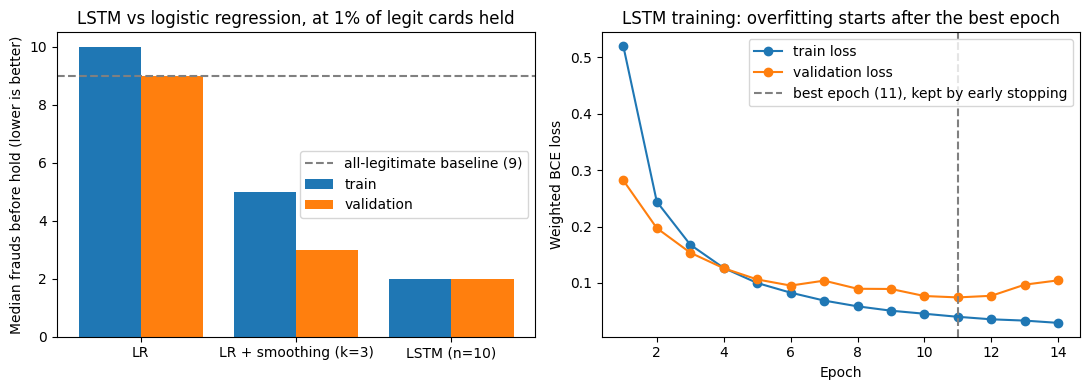

In [ ]:
import matplotlib.pyplot as plt
import os
os.makedirs("reports/figures", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Left: train vs validation for each model
names = list(results.keys())
tr = [results[n][0] for n in names]
va = [results[n][1] for n in names]
x = np.arange(len(names))
ax1.bar(x - 0.2, tr, width=0.4, label="train")
ax1.bar(x + 0.2, va, width=0.4, label="validation")
ax1.axhline(9, color="grey", linestyle="--", label="all-legitimate baseline (9)")
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_ylabel("Median frauds before hold (lower is better)")
ax1.set_title("LSTM vs logistic regression, at 1% of legit cards held")
ax1.legend()

# Right: LSTM loss curves
ep = [h["epoch"] for h in history]
ax2.plot(ep, [h["train_loss"] for h in history], marker="o", label="train loss")
ax2.plot(ep, [h["valid_loss"] for h in history], marker="o", label="validation loss")
best = min(history, key=lambda h: h["valid_loss"])["epoch"]
ax2.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best}), kept by early stopping")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Weighted BCE loss")
ax2.set_title("LSTM training: overfitting starts after the best epoch")
ax2.legend()

plt.tight_layout()
plt.savefig("reports/figures/d2_experiment.png", dpi=150)
plt.show()

In [ ]:
import pandas as pd

def operating_point(y, s, cards, max_rate=0.01):
    """Card-level precision and recall at the threshold the headline metric uses."""
    df = pd.DataFrame({"card": np.asarray(cards), "y": np.asarray(y).astype(int), "s": np.asarray(s, dtype=float)})
    per_card = df.groupby("card", sort=False).agg(attacked=("y", "max"), max_score=("s", "max"))
    legit = np.sort(per_card.loc[per_card["attacked"] == 0, "max_score"].to_numpy())
    cand = np.append(np.unique(df["s"]), np.inf)
    rate = (len(legit) - np.searchsorted(legit, cand, side="left")) / len(legit)
    t = cand[np.argmax(rate <= max_rate)]                       # same threshold rule as the metric

    df["pos"] = df.groupby("card", sort=False).cumcount()        # step number within each card
    first_hold = df[df["s"] >= t].groupby("card", sort=False)["pos"].min()
    last_fraud = df[df["y"] == 1].groupby("card", sort=False)["pos"].max()

    held = per_card.index.isin(first_hold.index)
    attacked = per_card["attacked"].to_numpy() == 1
    caught = last_fraud.index[first_hold.reindex(last_fraud.index) <= last_fraud]   # held while fraud ongoing

    precision = (held & attacked).sum() / held.sum() if held.sum() else float("nan")
    recall = len(caught) / attacked.sum()
    return t, precision, recall

rows = {
    "All-legitimate": (valid["is_fraud"], np.zeros(len(valid)), valid["cc_num"]),
    "LR": (valid["is_fraud"], s_lr_va, valid["cc_num"]),
    "LR + smoothing (k=3)": (valid["is_fraud"], models.smooth_scores(s_lr_va, valid["cc_num"]), valid["cc_num"]),
    "LSTM (n=10)": (meta_va["is_fraud"], s_lstm, meta_va["cc_num"]),
}
for name, (y_, s_, c_) in rows.items():
    t, p, r = operating_point(y_, s_, c_)
    print(f"{name:22s} threshold {t:.4f} | precision {p:.2f} | recall {r:.2f}")

All-legitimate         threshold inf | precision nan | recall 0.00
LR                     threshold 0.9998 | precision 0.50 | recall 0.02
LR + smoothing (k=3)   threshold 0.9772 | precision 0.97 | recall 0.92
LSTM (n=10)            threshold 0.9992 | precision 0.97 | recall 0.96


In [ ]:
for name, (y_, s_, c_) in rows.items():
    t, p, r = operating_point(y_, s_, c_)
    log_run(name, "validation, 1% legit-card budget", "precision_cards", round(float(p), 3) if p == p else "nan")
    log_run(name, "validation, 1% legit-card budget", "recall_cards", round(float(r), 3))

!git pull --rebase
!git add experiments/log.csv
!git commit -m "Log card-level precision and recall at the operating point"
!git push

error: cannot pull with rebase: You have unstaged changes.
error: Please commit or stash them.
[main 2677d01] Log card-level precision and recall at the operating point
 1 file changed, 8 insertions(+)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 559 bytes | 559.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   2d1f443..2677d01  main -> main


In [ ]:
import config

t_lstm, _, _ = operating_point(meta_va["is_fraud"], s_lstm, meta_va["cc_num"])

ev = meta_va[["cc_num", "is_fraud", "n_valid"]].copy()
ev["score"] = s_lstm
ev = ev.join(pool[["trans_date_trans_time", "amt", "category"]])
ev["gap_min"] = (np.expm1(feats.loc[ev.index, "log_seconds_since_prev"]) / 60).round(1)

g = ev.groupby("cc_num", observed=True, sort=False)
ev["flag"] = ev["score"] >= t_lstm                  # this transaction crosses the threshold
ev["held"] = g["flag"].cummax()                     # card already held at this transaction
ev["fraud_no"] = g["is_fraud"].cumsum()             # 1st, 2nd, 3rd... fraud on the card
ev["card_attacked"] = g["is_fraud"].transform("max")

missed = ev[(ev["is_fraud"] == 1) & (~ev["held"])]
false_holds = ev[(ev["card_attacked"] == 0) & ev["flag"]].groupby("cc_num", observed=True).head(1)

print("threshold:", round(t_lstm, 4))
print("missed frauds:", len(missed), "| honest cards held:", len(false_holds))
print("\nwhich fraud in the burst got through (1 = first fraud on the card):")
print(missed["fraud_no"].value_counts().sort_index().head(10))

threshold: 0.9992
missed frauds: 565 | honest cards held: 6

which fraud in the burst got through (1 = first fraud on the card):
fraud_no
1    232
2    176
3     86
4     42
5     16
6      6
7      5
8      2
Name: count, dtype: int64


In [ ]:
cols = ["trans_date_trans_time", "amt", "category", "gap_min", "n_valid", "fraud_no", "score"]

print("=== 5 random missed frauds ===")
print(missed.sample(5, random_state=config.SEED)[cols].to_string())

print("\n=== 5 random false holds (honest cards) ===")
print(false_holds.sample(5, random_state=config.SEED)[cols[:-2] + ["score"]].to_string())

=== 5 random missed frauds ===
        trans_date_trans_time         amt        category     gap_min  n_valid  fraud_no     score
979286    2020-02-02 01:41:23  286.359985     grocery_pos   10.100000       10         3  0.993592
1278638   2020-06-14 23:33:40   24.750000  health_fitness   15.600000       10         4  0.998168
1062873   2020-03-17 01:01:04   19.540001   gas_transport  926.799988       10         1  0.925739
1206799   2020-05-19 09:25:17   11.020000   gas_transport  912.400024       10         1  0.758803
1168468   2020-05-03 03:03:19  514.169983   entertainment  342.299988       10         1  0.983835

=== 5 random false holds (honest cards) ===
        trans_date_trans_time          amt      category      gap_min  n_valid     score
1238710   2020-05-31 22:30:02  4803.649902  shopping_pos   552.700012       10  0.999175
981655    2020-02-03 01:46:59  4169.500000  shopping_pos   649.400024       10  0.999666
1150591   2020-04-25 00:07:36   188.910004   grocery_pos     0.

In [ ]:
import json
with open("models/thresholds.json", "w") as f:
    json.dump({"hold": float(t_lstm)}, f, indent=2)
print(float(t_lstm))

0.9991745352745056


In [ ]:
!git pull --rebase
!git add models/thresholds.json
!git commit -m "D2.6: save LSTM operating-point threshold"
!git push

Already up to date.
[main 5d35833] D2.6: save LSTM operating-point threshold
 1 file changed, 3 insertions(+)
 create mode 100644 models/thresholds.json
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 413 bytes | 413.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   2677d01..5d35833  main -> main


In [ ]:
import importlib
from src import predict
importlib.reload(predict)

m = predict.load_model()
print("window:", m["n"], "| features:", len(m["features"]), "| threshold:", m["threshold"])

window: 10 | features: 17 | threshold: 0.9991745352745056


In [ ]:
!python -m pytest -q tests/test_predict.py

...                                                                      [100%]
3 passed in 5.05s


In [ ]:
!git pull --rebase
!git add src/predict.py
!git commit -m "D2.6: predict() with the LSTM, threshold and reasons; tests pass"
!git push
!git status

error: cannot pull with rebase: You have unstaged changes.
error: Please commit or stash them.
[main e2c0e47] D2.6: predict() with the LSTM, threshold and reasons; tests pass
 1 file changed, 66 insertions(+), 8 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.60 KiB | 1.60 MiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   5d35833..e2c0e47  main -> main
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	reports/figures/d2_experiment.png

nothing added to commit but untracked files present (use "git add" to track)


In [ ]:
!git add reports/figures/d2_experiment.png
!git commit -m "D2: experiment plot (LSTM vs LR, loss curves)"
!git pull --rebase
!git push

[main 585c6af] D2: experiment plot (LSTM vs LR, loss curves)
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 reports/figures/d2_experiment.png
Current branch main is up to date.
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 88.32 KiB | 5.52 MiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   e2c0e47..585c6af  main -> main


In [ ]:
print((len(y_tr) - y_tr.sum()) / y_tr.sum())

176.1743295019157


In [ ]:
import pandas as pd
log = pd.read_csv("experiments/log.csv")

rename = {
    "All-legitimate":       ("all_legitimate", "score 0 everywhere"),
    "LR":                   ("logistic_regression", "+ amount bands"),
    "LR + smoothing (k=3)": ("logistic_regression", "+ amount bands + smoothing k=3"),
    "LSTM (n=10)":          ("lstm", "n=10, hidden=32, lr=1e-3, batch 2048, pos_weight, early stop (best epoch 11)"),
}
for old, (new_model, new_settings) in rename.items():
    rows = log["model"] == old
    log.loc[rows, "model"] = new_model
    log.loc[rows, "settings"] = new_settings
    log.loc[rows, "notes"] = "card-level, 1% legit-card budget"

log.to_csv("experiments/log.csv", index=False)
print(log[["model", "settings", "metric", "value"]].tail(8).to_string())

                  model                                                                      settings           metric  value
9        all_legitimate                                                            score 0 everywhere  precision_cards    NaN
10       all_legitimate                                                            score 0 everywhere     recall_cards  0.000
11  logistic_regression                                                                + amount bands  precision_cards  0.500
12  logistic_regression                                                                + amount bands     recall_cards  0.017
13  logistic_regression                                                + amount bands + smoothing k=3  precision_cards  0.973
14  logistic_regression                                                + amount bands + smoothing k=3     recall_cards  0.920
15                 lstm  n=10, hidden=32, lr=1e-3, batch 2048, pos_weight, early stop (best epoch 11)  precision_cards

In [ ]:
!git add experiments/log.csv
!git commit -m "Tidy model names in log"
!git pull --rebase
!git push

[main c2fd876] Tidy model names in log
 1 file changed, 17 insertions(+), 17 deletions(-)
remote: Enumerating objects: 15, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 12 (delta 7), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (12/12), 111.89 KiB | 3.86 MiB/s, done.
From https://github.com/williamli218/mais202-team-2-fraud-bursts
   585c6af..72f928a  main       -> origin/main
Successfully rebased and updated refs/heads/main.
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 527 bytes | 527.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   72f928a..6f88843  main -> main


In [ ]:
import importlib
from src import features, predict
importlib.reload(features); importlib.reload(predict)

print("same columns as training:", predict.load_model()["features"] == features.LSTM_COLS)
!python -m pytest -q tests/test_predict.py


same columns as training: True
...                                                                      [100%]
3 passed in 3.14s


In [ ]:
!git add src/features.py src/predict.py
!git commit -m "One function for LSTM inputs, used by training and predict()"
!git pull --rebase
!git push

[main 398d08b] One function for LSTM inputs, used by training and predict()
 2 files changed, 17 insertions(+), 4 deletions(-)
Current branch main is up to date.
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 850 bytes | 850.00 KiB/s, done.
Total 5 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 4 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   366b638..398d08b  main -> main


In [ ]:
import numpy as np, torch
from src import data, features, predict, metrics, models

m = predict.load_model()                       # saved LSTM, mean/std, threshold

pool_f = pool.join(features.build_lstm_inputs(pool))
X, y, meta = data.make_sequences(pool_f, n=m["n"], feature_cols=m["features"])

# same scaling as training, using the saved numbers
X -= m["mean"]; X /= m["std"]
pad = np.arange(X.shape[1])[None, :] < (X.shape[1] - meta["n_valid"].to_numpy())[:, None]
X[pad] = 0.0

is_va = meta.index.isin(valid.index)
X_va, meta_va = X[is_va], meta[is_va]

s_va = models.lstm_scores(m["lstm"], X_va)
amt_va = pool.loc[meta_va.index, "amt"].to_numpy()

print("check, should be 2.0:", metrics.median_frauds_before_hold(
    meta_va["is_fraud"], s_va, meta_va["cc_num"], max_legit_hold_rate=0.01))

check, should be 2.0: 2.0


In [ ]:
import importlib
from src import decision
importlib.reload(decision)

curve = decision.cost_curve(meta_va["is_fraud"], s_va, amt_va, meta_va["cc_num"])
best = decision.choose_thresholds(meta_va["is_fraud"], s_va, amt_va, meta_va["cc_num"])
print(best)
print(curve[curve["threshold"] == best["hold"]].to_string())

{'hold': 0.9991763234138489}
        threshold  legit_cards_held  legit_hold_rate  frauds_missed  missed_fraud_cost     total_cost
365386   0.999176                 5         0.007205            565      233394.480176  233469.480176


In [ ]:
print(curve[curve["threshold"] >= 0.99917453].head(3).to_string())

        threshold  legit_cards_held  legit_hold_rate  frauds_missed  missed_fraud_cost     total_cost
365385   0.999175                 6         0.008646            565      233394.480176  233484.480176
365386   0.999176                 5         0.007205            565      233394.480176  233469.480176
365387   0.999184                 5         0.007205            565      233394.480176  233469.480176


In [ ]:
best = decision.choose_thresholds(meta_va["is_fraud"], s_va, amt_va, meta_va["cc_num"],
                                  path="models/thresholds.json")
print(open("models/thresholds.json").read())

!git add src/decision.py models/thresholds.json
!git commit -m "D3.1: cost-based hold threshold on validation (5 legit cards held, total $233,469)"
!git pull --rebase
!git push

{
  "hold": 0.9991763234138489
}
[main 9cf2a98] D3.1: cost-based hold threshold on validation (5 legit cards held, total 233,469)
 2 files changed, 57 insertions(+), 11 deletions(-)
Current branch main is up to date.
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (6/6), 2.60 KiB | 2.60 MiB/s, done.
Total 6 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   bc29ec6..9cf2a98  main -> main


In [ ]:
import pandas as pd

t = pd.to_datetime(train["trans_date_trans_time"])
fraud = train[train["is_fraud"] == 1]
span = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].agg(["min", "max"])
hours = (span["max"] - span["min"]).dt.total_seconds() / 3600

print("attacks:", len(hours))
print("attack length in hours:")
print(hours.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

attacks: 527
attack length in hours:
count    527.0
mean      40.3
std        9.1
min        0.1
50%       45.1
90%       47.2
95%       47.4
99%       47.7
max       47.9
dtype: float64


In [ ]:
importlib.reload(decision)
times_va = pool.loc[meta_va.index, "trans_date_trans_time"]
dec = decision.simulate_holds(s_va, meta_va["cc_num"], times_va, best["hold"], hold_hours=72)

yv = meta_va["is_fraud"].to_numpy()
cards = meta_va["cc_num"].to_numpy()
slipped = (yv == 1) & (dec == "allow")

per_card = pd.DataFrame({"card": cards, "y": yv, "slip": slipped, "held": dec == "hold"}).groupby("card")
attacked = per_card["y"].max() == 1
legit_held = int(((~attacked) & per_card["held"].max()).sum())
median_slip = per_card["slip"].sum()[attacked].median()

print("72h + re-hold: fraud charges through", int(slipped.sum()),
      "| median per attacked card", median_slip,
      "| honest cards held", legit_held,
      "| total cost $%.0f" % (15 * legit_held + amt_va[slipped].sum()))
print("hold forever:  fraud charges through 565 | median 2.0 | honest cards held 5 | total cost $233,469")

72h + re-hold: fraud charges through 568 | median per attacked card 2.0 | honest cards held 5 | total cost $234459
hold forever:  fraud charges through 565 | median 2.0 | honest cards held 5 | total cost $233,469


In [ ]:
import json
with open("models/thresholds.json", "w") as f:
    json.dump({"hold": best["hold"], "hold_hours": 72}, f, indent=2)
print(open("models/thresholds.json").read())

!git add src/decision.py models/thresholds.json
!git commit -m "D3.1: cost-based threshold + 72h hold with re-scoring"
!git pull --rebase
!git push

{
  "hold": 0.9991763234138489,
  "hold_hours": 72
}
[main 463081d] D3.1: cost-based threshold + 72h hold with re-scoring
 2 files changed, 25 insertions(+), 1 deletion(-)
Current branch main is up to date.
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (6/6), 1.00 KiB | 1.00 MiB/s, done.
Total 6 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 4 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   9cf2a98..463081d  main -> main


In [ ]:
import importlib
from src import decision, predict
importlib.reload(decision); importlib.reload(predict)
!python -m pytest -q tests/test_predict.py

!git add src/predict.py
!git commit -m "D3: predict() replays the 72h hold over the card's recent transactions"
!git pull --rebase
!git push

...                                                                      [100%]
3 passed in 3.82s
[main 07befdc] D3: predict() replays the 72h hold over the card's recent transactions
 1 file changed, 28 insertions(+), 17 deletions(-)
Current branch main is up to date.
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.05 KiB | 1.05 MiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/williamli218/mais202-team-2-fraud-bursts
   463081d..07befdc  main -> main


In [ ]:
for hours in [24, 48, 72, 96]:
    print(f"{hours:3d}h", decision.evaluate(s_va, meta_va["cc_num"], meta_va["is_fraud"],
                                            amt_va, times_va, best["hold"], hours))